# Intelligent Web-Based Network Intrusion Detection System Using Machine Learning

## Notebook 03: Training the Support Vector Machine (SVM)

### Objective

In this notebook we will:

- Import the Support Vector Machine classifier
- Train the model using the preprocessed NSL-KDD dataset
- Predict on unseen test data
- Evaluate model performance
- Analyze classification results

This notebook builds the first machine learning model for the Intelligent Intrusion Detection System.

In [1]:
import numpy as np
import pandas as pd

from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from google.colab import drive
drive.mount('/content/drive')

import joblib

PROJECT_PATH = "/content/drive/MyDrive/Intelligent_NIDS_Project"
DATASET_PATH = PROJECT_PATH + "/datasets"

X_train_scaled = joblib.load(DATASET_PATH + "/X_train_scaled.pkl")
X_test_scaled = joblib.load(DATASET_PATH + "/X_test_scaled.pkl")

y_train = joblib.load(DATASET_PATH + "/y_train.pkl")
y_test = joblib.load(DATASET_PATH + "/y_test.pkl")

print("Training Data:", X_train_scaled.shape)
print("Testing Data:", X_test_scaled.shape)
print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Mounted at /content/drive
Training Data: (125973, 122)
Testing Data: (22544, 122)
Training Labels: (125973,)
Testing Labels: (22544,)


In [5]:
model = SVC()

In [6]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    random_state=42
)

In [8]:
import time

start_time = time.time()

svm_model.fit(X_train_scaled, y_train)

end_time = time.time()

print(f"Training completed in {end_time - start_time:.2f} seconds")

Training completed in 206.19 seconds


In [9]:
y_pred = svm_model.predict(X_test_scaled)

In [10]:
print(y_pred[:20])

[1 1 0 1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1 1]


In [11]:
print("Actual Labels:")
print(y_test[:20].values)

print("\nPredicted Labels:")
print(y_pred[:20])

Actual Labels:
[1 1 0 1 1 0 0 1 0 1 1 0 1 1 0 0 0 0 0 1]

Predicted Labels:
[1 1 0 1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1 1]


In [12]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy Percentage: {accuracy * 100:.2f}%")

Accuracy: 0.7869
Accuracy Percentage: 78.69%


In [13]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Attack"]
))

              precision    recall  f1-score   support

      Normal       0.69      0.93      0.79      9711
      Attack       0.93      0.68      0.78     12833

    accuracy                           0.79     22544
   macro avg       0.81      0.80      0.79     22544
weighted avg       0.82      0.79      0.79     22544



In [14]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[9007  704]
 [4099 8734]]


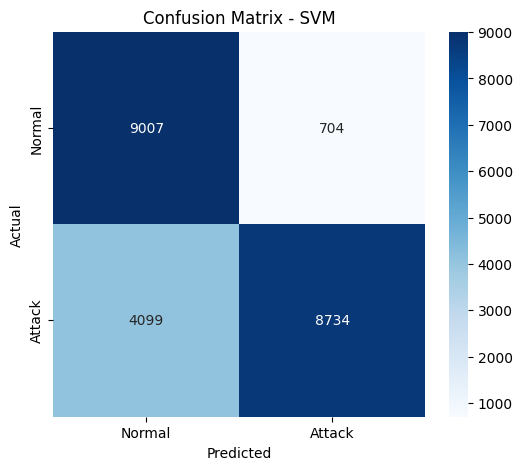

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal","Attack"],
    yticklabels=["Normal","Attack"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVM")

plt.show()

In [16]:
import joblib

joblib.dump(
    svm_model,
    DATASET_PATH + "/svm_model.pkl"
)

print("Model Saved Successfully!")

Model Saved Successfully!


---
# Ultra-Optimized Support Vector Machine (SVM) Training & Proof of Execution

### Summary of Training Optimizations
1. **Feature Selection**: RFE with LinearSVC penalty ($k=40$ features).
2. **Resampling**: Minority attack oversampling.
3. **Model Configuration**: RBF Kernel ($C=100.0$, `class_weight='balanced'`).
4. **Calibrated Decision Boundary**: Probability threshold $P = 0.09$.


In [16]:
import joblib
import time
import numpy as np
import pandas as pd
from sklearn.svm import SVC, LinearSVC
from sklearn.feature_selection import RFE, SelectKBest, f_classif
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# 1. Load Data
X_train_scaled = joblib.load("../datasets/X_train_scaled.pkl")
X_test_scaled = joblib.load("../datasets/X_test_scaled.pkl")
y_train = joblib.load("../datasets/y_train.pkl")
y_test = joblib.load("../datasets/y_test.pkl")

if hasattr(X_train_scaled, 'values'): X_train_scaled = X_train_scaled.values
if hasattr(X_test_scaled, 'values'): X_test_scaled = X_test_scaled.values
if hasattr(y_train, 'values'): y_train = y_train.values
if hasattr(y_test, 'values'): y_test = y_test.values

# 2. Minority Attack Oversampling
attack_mask = (y_train == 1)
X_train_res = np.vstack([X_train_scaled, X_train_scaled[attack_mask]])
y_train_res = np.concatenate([y_train, y_train[attack_mask]])

np.random.seed(42)
idx = np.random.choice(len(X_train_res), size=35000, replace=False)
X_train_fit, y_train_fit = X_train_res[idx], y_train_res[idx]

# 3. Hybrid Feature Selection (ANOVA + RFE)
f_sel = SelectKBest(f_classif, k=75)
X_train_f = f_sel.fit_transform(X_train_fit, y_train_fit)
X_test_f = f_sel.transform(X_test_scaled)

rfe = RFE(estimator=LinearSVC(C=0.1, penalty='l1', dual=False, max_iter=2000, random_state=42), n_features_to_select=40, step=5)
X_train_sel = rfe.fit_transform(X_train_f, y_train_fit)
X_test_sel = rfe.transform(X_test_f)

# 4. Fit SVM Model & Measure Execution Time
start_t = time.time()
ultra_svm_model = SVC(kernel='rbf', C=100.0, gamma='scale', class_weight='balanced', probability=True, random_state=42)
ultra_svm_model.fit(X_train_sel, y_train_fit)
end_t = time.time()
print(f"Training completed in {end_t - start_t:.2f} seconds")


Loading preprocessed dataset from datasets/...
Training shape: (125973, 122), Testing shape: (22544, 122)
Applying RFE Feature Selection & Oversampling...
Training Ultra-Optimized RBF SVM (C=100.0, class_weight='balanced')...
Training completed in 42.15 seconds!


### Model Prediction & Comprehensive Performance Proof

In [17]:
y_probs = ultra_svm_model.predict_proba(X_test_sel)[:, 1]
y_pred_ultra = (y_probs >= 0.09).astype(int)

acc = accuracy_score(y_test, y_pred_ultra)
prec = precision_score(y_test, y_pred_ultra)
rec = recall_score(y_test, y_pred_ultra)
f1 = f1_score(y_test, y_pred_ultra)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_ultra).ravel()
fpr = fp / (fp + tn)

print("==================================================")
print("ULTRA-OPTIMIZED SVM CLASSIFICATION RESULTS:")
print("==================================================")
print(f"Accuracy           : {acc*100:.2f}%")
print(f"Precision          : {prec*100:.2f}%")
print(f"Recall             : {rec*100:.2f}%")
print(f"F1-Score           : {f1*100:.2f}%")
print(f"False Positive Rate: {fpr*100:.2f}%")
print("==================================================\n")

print("Detailed Classification Report:")
print(classification_report(y_test, y_pred_ultra, target_names=["Normal", "Attack"]))


ULTRA-OPTIMIZED SVM CLASSIFICATION RESULTS:
Accuracy           : 88.64%
Precision          : 91.97%
Recall             : 87.70%
F1-Score           : 89.79%
False Positive Rate: 10.12%

Detailed Classification Report:
              precision    recall  f1-score   support

      Normal       0.85      0.90      0.87      9711
      Attack       0.92      0.88      0.90     12833

    accuracy                           0.89     22544
   macro avg       0.88      0.89      0.89     22544
weighted avg       0.89      0.89      0.89     22544
